# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73213, Tomás Alexandre, tf.alexandre@campus.fct.unl.pt
- 77580, Ana Francisco, am.francisco@campus.fct.unl.pt

## 1. Introduction

## 2. Part 1 - Frame dissimilarity and hard cuts

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import json
import glob
import numpy as np
import matplotlib.pyplot as plt

from tp1 import (
    read_frames,
    compute_pixel_diff_signal,
    compute_histogram_signal,
    compute_ecr_signal
)
import plotting
import metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Task 1

In [ ]:
video_path = os.path.join("..", "input", "dev_01.mp4")

frames = read_frames(video_path)
total_frames = len(frames)

print(f"Total de frames: {total_frames}")
print(f"Resolução da primeira frame (H, W, C): {frames[0].shape}")

In [13]:
input_dir = os.path.join("..", "input")
dev_files = sorted(glob.glob(os.path.join(input_dir, "dev_*.mp4")))

dev_data = {}

for video_path in dev_files:
    name = os.path.splitext(os.path.basename(video_path))[0]
    json_path = os.path.join(input_dir, f"{name}.json")
    
    with open(json_path, "r") as f:
        gt = json.load(f)
        
    frames = read_frames(video_path)
    
    print(f"A calcular sinais para {name} ({len(frames)} frames)...")
    dev_data[name] = {
        "gt": gt,
        "frames": frames,
        "signals": {
            "Pixel Difference": compute_pixel_diff_signal(frames),
            "Histogram Distance (Chi2)": compute_histogram_signal(frames, bins=(16, 16)),
            "ECR": compute_ecr_signal(frames)
        }
    }

print("Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!")

A calcular sinais para dev_01 (3809 frames)...
A calcular sinais para dev_02 (3760 frames)...
Cálculo dos sinais concluído para todo o conjunto de desenvolvimento (DEV)!


## Task 2

### A. Pixel Difference (Baseline)
Calcula a média das diferenças absolutas dos níveis de cinzento entre $t-1$ e $t$. É sensível a movimentos globais de câmara e a variações de iluminação.

### B. Histogram Distance ($\chi^2$ em HSV)
HSV ou HSL, costuma ser mais robusto a variações de iluminação e sombras do que o espaço RGB que é mais simples, mas variações de brilho e iluminação alteram todos os canais e geram picos falsos de distância. Optou-se pelo espaço de cor **HSV** (usando os canais $H$ e $S$ com $16 \times 16$ *bins*) por ser mais robusto a variações de brilho/iluminação do que o RGB. A distância Qui-Quadrado ($\chi^2$) normalizada é calculada do zero com NumPy:
$$\chi^2(h_1, h_2) = \frac{1}{2} \sum_{i} \frac{(h_1[i] - h_2[i])^2}{h_1[i] + h_2[i]}$$

### C. Edge Change Ratio (ECR)

Limiares de Canny (low_thresh, high_thresh): 100 e 200 funcionam bem como base, mas podemos testar valores no conjunto dev para evitar apanhar demasiado ruído.   

Tamanho do Kernel (kernel_size): O enunciado sugere um kernel 5×5. Se usarmos frames muito pequenas (ex: 320×180) ***#TODO*** , um kernel 3×3 ou 5×5 é o ideal para cobrir movimentos de 1 a 2 pixels.



Mede a fração de contornos que entram ($X_t^{in}$) ou saem ($X_t^{out}$) entre $t-1$ e $t$, usando Canny e dilatação ($5 \times 5$) para permitir uma pequena margem de tolerância ao movimento do objeto/câmara.

### Deliverable A — Gráfico dos Sinais (~30 Segundos)
Visualização dos três sinais de dissimilaridade calculados nos primeiros 30 segundos do vídeo `dev_01`, com as linhas verticais dos cortes reais e *flashes* do *ground-truth* sobrepostas.

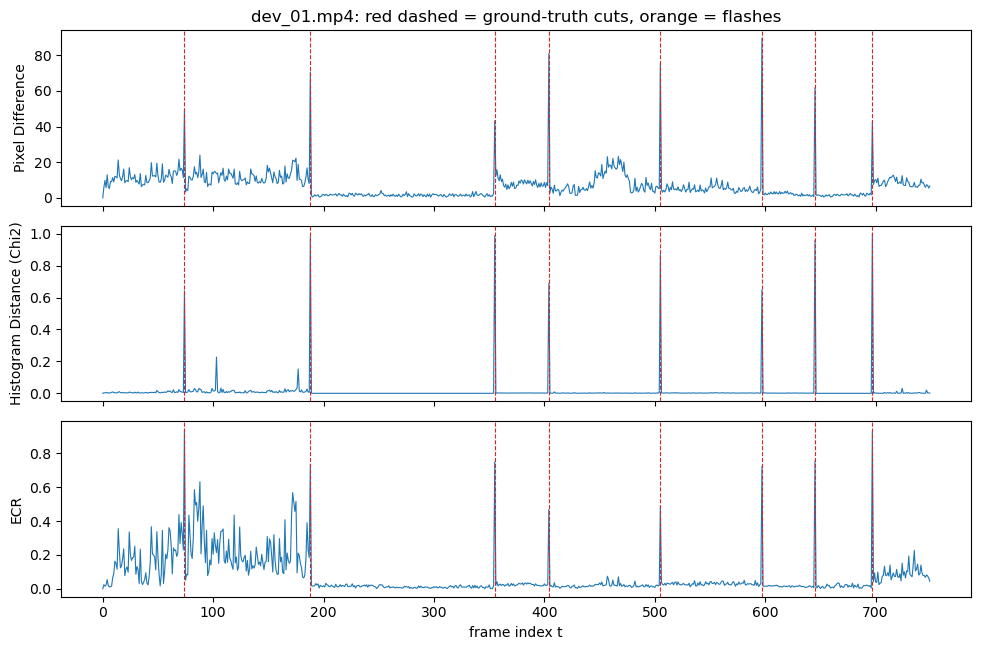

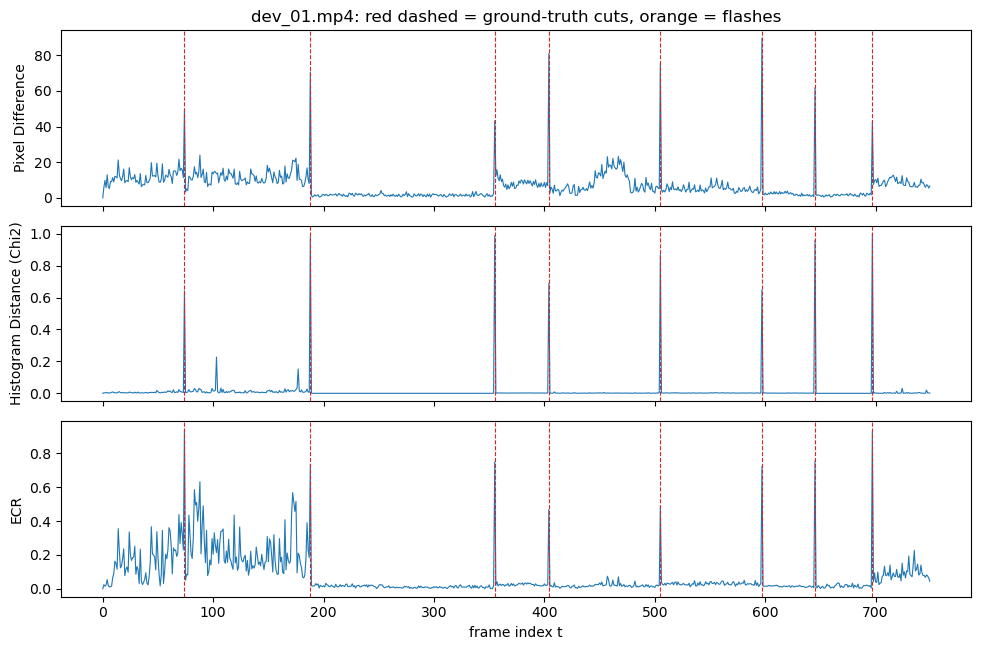

In [14]:
dev01_gt = dev_data["dev_01"]["gt"]
fps = dev01_gt.get("fps", 25)

# Visualizar os primeiros 30 segundos (30 * fps)
plotting.plot_signals(
    signals=dev_data["dev_01"]["signals"],
    gt=dev01_gt,
    start=0,
    end=30 * fps
)

### Deliverable A — Varrimento de Limiares e Tabela de Comparação
A escolha dos limiares ($T$) é efetuada no conjunto total de desenvolvimento (`DEV` = `dev_01` + `dev_02`). Para cada sinal, varia-se o limiar $T$ ao longo de um intervalo de valores, contabilizando $TP$, $FP$ e $FN$ com a função `metrics.match_cuts`[cite: 5, 7].

In [15]:
signal_names = ["Pixel Difference", "Histogram Distance (Chi2)", "ECR"]
pr_curves_data = {}
best_results = {}

for s_name in signal_names:
    # Determinar valor máximo do sinal em todo o DEV
    max_val = max(np.max(dev_data[v]["signals"][s_name]) for v in dev_data)
    thresholds = np.linspace(0, max_val, 200)
    
    points = []
    best_f1, best_p, best_r, best_t = -1.0, 0.0, 0.0, 0.0
    
    for t in thresholds:
        total_tp, total_fp, total_fn = 0, 0, 0
        
        for name, data in dev_data.items():
            sig = data["signals"][s_name]
            gt_cuts = [trans["start"] for trans in data["gt"]["transitions"] if trans["type"] == "cut"]
            pred_cuts = np.where(sig > t)[0].tolist()
            
            tp, fp, fn = metrics.match_cuts(pred_cuts, gt_cuts)
            total_tp += tp
            total_fp += fp
            total_fn += fn
            
        p, r, f1 = metrics.precision_recall_f1(total_tp, total_fp, total_fn)
        points.append((t, p, r))
        
        if f1 > best_f1:
            best_f1, best_p, best_r, best_t = f1, p, r, t
            
    pr_curves_data[s_name] = points
    best_results[s_name] = (best_t, best_p, best_r, best_f1)

# Imprimir Tabela Formatada para o Relatório
print(f"{'Sinal':<28} | {'Limiar Ótimo (T)':<16} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 82)
for s_name, (t, p, r, f1) in best_results.items():
    print(f"{s_name:<28} | {t:<16.4f} | {p:<10.3f} | {r:<10.3f} | {f1:<10.3f}")

Sinal                        | Limiar Ótimo (T) | Precision  | Recall     | F1-Score  
----------------------------------------------------------------------------------
Pixel Difference             | 46.8682          | 0.943      | 0.680      | 0.790     
Histogram Distance (Chi2)    | 0.3015           | 0.943      | 0.695      | 0.800     
ECR                          | 0.7186           | 0.557      | 0.661      | 0.605     


### Deliverable A — Curvas Precision-Recall (PR)
Visualização das curvas PR obtidas no varrimento de limiares para os três sinais de dissimilaridade no conjunto `DEV`. Os pontos de $F_1$ máximo de cada sinal encontram-se marcados no gráfico.

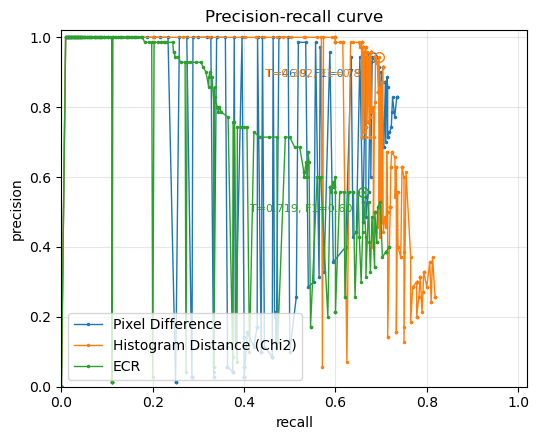

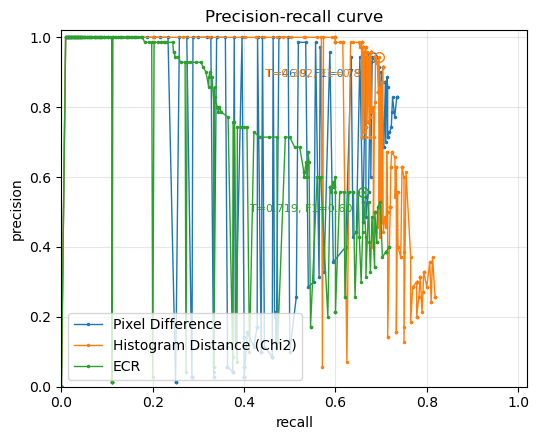

In [16]:
# Gerar o gráfico das curvas PR usando a função dada
plotting.plot_pr_curve(pr_curves_data)

## 3. Part 2 - Gradual transitions and false alarms

## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools